# 12 - Core Calibration and the Digital Core

**Part B - Petrophys Curriculum**

Wireline logs are *indirect* measurements. A neutron tool counts hydrogen, a
density tool counts back-scattered gamma rays - neither one *is* porosity. The
ground truth against which every log interpretation is ultimately judged is the
**core**: a physical cylinder of rock brought to surface and measured in the
laboratory.

This lesson has two halves:

1. **Core-to-log calibration** - tie laboratory helium porosity and Klinkenberg
   permeability to the logs, quantify the mismatch ($R^2$, bias, RMSE), and fit a
   **poro-perm transform** so we can predict permeability everywhere the core did
   not sample.
2. **Rock typing on the cored interval** - cluster real wireline logs into
   **electrofacies** with weighted K-means (`DigitalCoreFacies`), fingerprint
   each cluster with per-facies statistics, and read the clusters on a
   density-neutron cross-plot.

Everything in this lesson runs on the real cored well **30/6-5** (Oseberg,
North Sea). The library also ships digital-core readers for scanner data
(`XRFData`, `GrainSizeData`, `CoreMechanical`); 30/6-5 has no scanner
measurements, so those tools are referenced but not demonstrated - we do not
plot data that was never measured.

## Learning goals

By the end of this lesson you will be able to:

- Build a `CoreData` container directly from a cored well with
  `petrophys.model.core_from_well`.
- Calibrate a log-derived porosity against core with `calibrate_porosity`, and
  read the calibration statistics off a `CalibrationResult`.
- Fit a linear porosity correction (`fit_porosity_correction`) and a poro-perm
  transform (`fit_poro_perm_transform`), then apply the transform to the log.
- Cluster multi-parameter core data into facies with `DigitalCoreFacies` /
  `FaciesResult`, and produce a per-facies statistics table.

## Why this matters

Every deterministic petrophysical answer - porosity, saturation, net pay,
volumes - inherits the systematic error of the logs it was built from. Core
calibration is how we *anchor* those logs to reality:

- **Porosity** measured by a density tool depends on an assumed matrix density.
  Get the grain density wrong and every porosity is biased. Core helium porosity
  fixes the tie point.
- **Permeability** is never measured by wireline; it is *always* a correlation.
  A poro-perm transform fitted to core plugs is the standard way to propagate a
  handful of lab measurements to the full log.

The **digital core** pushes this further. Instead of one plug every ~30 cm,
modern core scanners deliver *continuous* millimetre-to-centimetre logs of grain
size, elemental chemistry, strength, and colour. Clustering these into facies
gives a rock-typing scheme that is fully data-driven and reproducible - the
workflow used by service companies such as EpsLog / Stratum Reservoir.

> **Units convention.** In `petrophys`, porosity and saturation are stored as
> **fractions (v/v, 0-1)**, permeability in **mD**, and grain/bulk density in
> **g/cm3**.

### Prerequisites

Assumes the Part A porosity and permeability lessons (04, 08). The digital-core
tools depend on **scikit-learn** for K-means clustering; this is installed in the
tutorial kernel.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)
print('geolink wells:', petrophys.list_samples('geolink'))

petrophys 0.1.0
geolink wells: ['15_9-14', '16_7-1', '25_5-1', '30_6-5']


---
## Part 1 - Core-to-log calibration

### 1.1 Loading core measurements from the well

Well **30/6-5** is unusual and convenient: it ships with the laboratory core
measurements already merged into the LAS file as dedicated curves -
`PHIC` (core helium porosity), `KH_CORE` (horizontal Klinkenberg permeability),
`GDEN` (grain density), and `SWC` / `SOC` (Dean-Stark saturations).

`core_data_from_well` sweeps the well for these mnemonics and packs the samples
that actually carry a lab measurement into a `CoreData` object.

In [2]:
well = read_las(petrophys.sample('30_6-5'))

# Sanitize the field name for ASCII printing (this header has mojibake).
field_ascii = (well.header.field or 'Unknown').encode('ascii', 'replace').decode('ascii')
print('Well :', well.name, '| field:', field_ascii)
print('Depth: %.1f - %.1f %s' % (well.start_depth, well.stop_depth, well.depth_unit))
print('Curves present:', ', '.join(well.curves))

Well : 30/6-5 | field: OSEBERG ??ST
Depth: 176.6 - 3556.1 m
Curves present: LITHOLOGY_GEOLINK, CALI, DRHO, NPHI, RHOB, PEF, GR, DTC, DTE, RDEP, SP, RSHA, RMED, BS, PHIC, GDEN, KH_CORE, KV_CORE, SWC, SOC


In [3]:
from petrophys.interpretation.core_analysis import core_data_from_well

core = core_data_from_well(well)
print(core)
print()
print('Plugs                :', core.n_plugs)
print('Cored interval       : %.1f - %.1f %s' % (core.top, core.bottom, well.depth_unit))
print('Porosity source curve:', core.metadata.get('core_porosity_curve'))
print('Perm source curve    :', core.metadata.get('core_permeability_curve'))
print('GD source curve      :', core.metadata.get('core_grain_density_curve'))
print()
print('Valid porosity plugs :', int(np.isfinite(core.porosity).sum()))
print('Valid perm plugs     :', int(np.isfinite(core.permeability).sum()))
print('Core porosity range  : %.3f - %.3f v/v' % (np.nanmin(core.porosity), np.nanmax(core.porosity)))
print('Core perm range      : %.2f - %.1f mD' % (np.nanmin(core.permeability), np.nanmax(core.permeability)))

CoreData(plugs=201, depth=2800.5-2947.9, props=[porosity, perm, GD, Sw])

Plugs                : 201
Cored interval       : 2800.5 - 2947.9 m
Porosity source curve: PHIC
Perm source curve    : KH_CORE
GD source curve      : GDEN

Valid porosity plugs : 200
Valid perm plugs     : 198
Core porosity range  : 0.022 - 0.277 v/v
Core perm range      : 0.02 - 5826.0 mD


### 1.2 Calibrating an *independent* log porosity

To calibrate honestly we must compare core against a log porosity that was
computed **independently** of the core. (Comparing `PHIC` against itself would
trivially give $R^2 = 1$.) So we compute a fresh **density porosity** from the
bulk-density curve using the textbook relation

$$\phi_D = \frac{\rho_{ma} - \rho_b}{\rho_{ma} - \rho_f}$$

with an *assumed* sandstone matrix density $\rho_{ma} = 2.65$ g/cm3 and fluid
density $\rho_f = 1.0$ g/cm3. The whole point of calibration is to discover how
wrong those assumptions are.

In [4]:
RHO_MA = 2.65   # assumed quartz matrix density (g/cm3)
RHO_F  = 1.00   # assumed fluid density (g/cm3)

rhob = np.asarray(well.get('RHOB').data, dtype=float)
phid = np.clip((RHO_MA - rhob) / (RHO_MA - RHO_F), 0.0, 0.5)
well.add_curve('PHID', phid, 'v/v', 'Density porosity (rho_ma=2.65)')

print('PHID added. Mean density porosity: %.3f v/v' % np.nanmean(phid))

PHID added. Mean density porosity: 0.286 v/v


In [5]:
from petrophys.interpretation.core_analysis import calibrate_porosity

cal = calibrate_porosity(well, core, log_curve='PHID')
print('Core vs log density-porosity calibration')
print('  n points  :', cal.n_points)
print('  R^2       : %.3f' % cal.r_squared)
print('  Bias (log-core): %+.4f v/v' % cal.bias)
print('  RMSE      : %.4f v/v' % cal.rmse)
print('  Linear fit: log = %.3f * core + %.4f' % (cal.slope, cal.intercept))

Core vs log density-porosity calibration
  n points  : 200
  R^2       : 0.645
  Bias (log-core): -0.0198 v/v
  RMSE      : 0.0461 v/v
  Linear fit: log = 0.860 * core + 0.0045


A **positive bias** means the log reads systematically *higher* than core; a
negative bias means it reads low. On 30/6-5 the density porosity runs slightly
**low** relative to core, and the scatter ($R^2 \approx 0.65$) reflects the
assumed matrix density not being exactly right for every plug - exactly the kind
of systematic error calibration exists to expose.

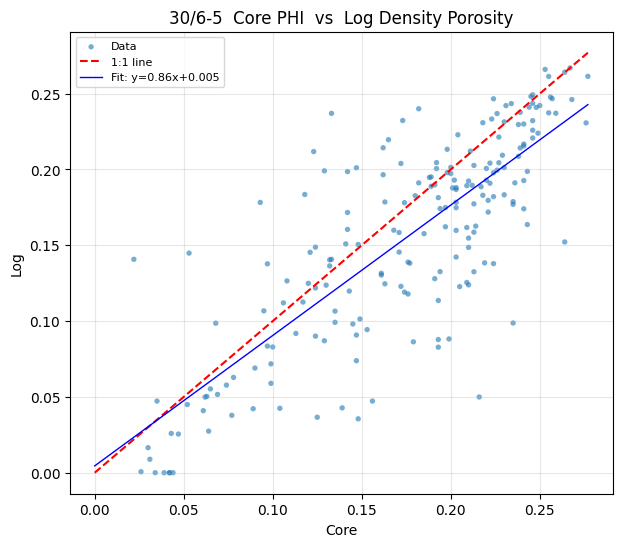

In [6]:
from petrophys.visualization.core import plot_calibration

fig, ax = plot_calibration(cal, title='30/6-5  Core PHI  vs  Log Density Porosity')
plt.show()

### 1.3 A porosity correction

`fit_porosity_correction` fits $\phi_{core} = A\,\phi_{log} + B$ so we can map
the *full* log porosity onto its core-equivalent value. This is the transfer
function you would apply downstream before computing volumes.

In [7]:
from petrophys.interpretation.core_analysis import fit_porosity_correction

corr = fit_porosity_correction(well, core, log_curve='PHID')
print(corr)
print()
# Apply to two example log readings
for phi_log in (0.10, 0.25):
    print('  log phi %.2f -> core-equivalent %.3f' % (phi_log, float(corr.predict(phi_log))))

PorosityCorrection(PHIcore = 0.717*PHID + 0.065, R^2=0.580, RMSE=0.0383, n=193)

  log phi 0.10 -> core-equivalent 0.136
  log phi 0.25 -> core-equivalent 0.244


### 1.4 Fitting a poro-perm transform

Permeability spans orders of magnitude, so the industry-standard transform is
linear in **log10** space:

$$\log_{10}(k) = A\,\phi + B \quad\Longleftrightarrow\quad k = 10^{B}\,10^{A\phi}$$

`fit_poro_perm_transform` fits this straight from the `CoreData` porosity and
permeability arrays.

In [8]:
from petrophys.interpretation.core_analysis import fit_poro_perm_transform

transform = fit_poro_perm_transform(core)
print('Poro-perm transform (log10 K = A*phi + B)')
print('  A (slope)    : %.2f' % transform.A)
print('  B (intercept): %.2f' % transform.B)
print('  R^2          : %.3f' % transform.r_squared)
print('  n plugs      :', transform.n_points)
print()
for phi in (0.10, 0.20, 0.30):
    print('  phi %.2f -> k = %.2f mD' % (phi, float(transform.predict(phi))))

Poro-perm transform (log10 K = A*phi + B)
  A (slope)    : 21.72
  B (intercept): -2.54
  R^2          : 0.777
  n plugs      : 198

  phi 0.10 -> k = 0.43 mD
  phi 0.20 -> k = 64.23 mD
  phi 0.30 -> k = 9540.29 mD


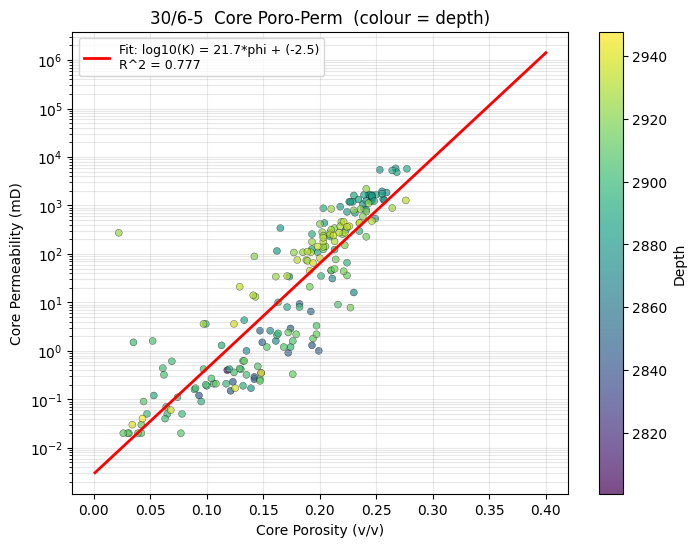

In [9]:
from petrophys.visualization.core import plot_poro_perm

fig, ax = plot_poro_perm(core, transform=transform,
                         title='30/6-5  Core Poro-Perm  (colour = depth)')
plt.show()

### 1.5 Applying the transform back onto the log

`apply_poro_perm_transform` writes a continuous predicted-permeability curve onto
the well using a chosen porosity input. We feed it our density porosity so the
prediction covers the *entire* logged interval, not just the cored plugs - the
whole reason for building the transform. We store it as `PERM_CORE`, a name the
core-overlay plotter recognises, so the next figure can overlay the measured
plugs on the prediction.

In [10]:
from petrophys.interpretation.core_analysis import apply_poro_perm_transform

perm_pred = apply_poro_perm_transform(well, transform,
                                      porosity_curve='PHID',
                                      output_curve='PERM_CORE')
print('Predicted permeability curve PERM_CORE added to well.')
finite = perm_pred[np.isfinite(perm_pred)]
print('  samples     :', finite.size)
print('  median k    : %.2f mD' % np.median(finite))
print('  P10 / P90   : %.2f / %.1f mD' % (np.percentile(finite, 10), np.percentile(finite, 90)))

Predicted permeability curve PERM_CORE added to well.
  samples     : 22171
  median k    : 41653.86 mD
  P10 / P90   : 0.03 / 100000.0 mD


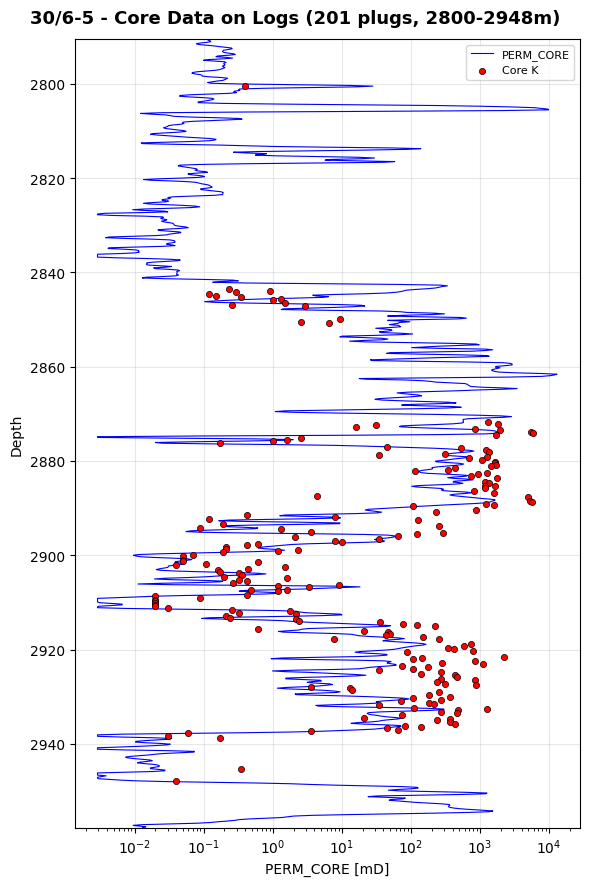

In [11]:
# Overlay: continuous predicted perm vs the discrete core plugs, over the cored interval.
# PERM_CORE is in plot_core_on_logs's core_map, so the core K plugs are overlaid
# automatically as red markers on the semilogx track (see core_map in visualization/core.py).
from petrophys.visualization.core import plot_core_on_logs

fig, axes = plot_core_on_logs(
    well, core,
    curves=['PERM_CORE'],
    depth_range=(core.top - 10, core.bottom + 10),
    figsize=(6, 9),
)
plt.show()

---
## Part 2 - Rock typing with the digital-core toolkit

Plug-based core analysis samples one point every ~30 cm. Modern **core scanning**
delivers *continuous* high-resolution logs: laser grain size, XRF elemental
chemistry, scratch-test strength, ultrasonic velocities, and RGB colour. The
`petrophys.interpretation.core_analysis` digital-core suite ingests these and turns them into
interpretation-ready products: `XRFData` (mineral proxies, elemental ratios),
`GrainSizeData` (Wentworth classes, sorting, Kozeny-Carman permeability), and
`CoreMechanical` (dynamic elastic moduli from Vp/Vs).

> **Data note.** 30/6-5 carries no scanner data, so those three tools are not
> demonstrated here: a synthetic demo log is a figure waiting to be mistaken
> for a measurement. What the well *does* support is the clustering member of
> the suite, `DigitalCoreFacies`, applied to real wireline logs over the cored
> interval - a standard electrofacies workflow.

### 2.1 Facies classification with weighted K-means

`DigitalCoreFacies` standardises each input feature, applies an optional
`sqrt(weight)` emphasis, and runs K-means. The result is a `FaciesResult`
carrying the per-sample labels, cluster centroids (back in original units), and
convenience methods `proportions()` and `statistics()`.

Here we use **real 30/6-5 wireline logs** (GR, RHOB, NPHI, PEF) over the cored
interval as the multi-parameter feature set - a legitimate electrofacies
exercise - to keep the demonstration grounded in real data.

In [12]:
from petrophys.interpretation.core_analysis import DigitalCoreFacies

# Real logs over the cored interval as clustering features.
top, bottom = core.top, core.bottom
dep = np.asarray(well.depth, dtype=float)
m = (dep >= top) & (dep <= bottom)

features = {
    'GR':   np.asarray(well.get('GR').data,   dtype=float)[m],
    'RHOB': np.asarray(well.get('RHOB').data, dtype=float)[m],
    'NPHI': np.asarray(well.get('NPHI').data, dtype=float)[m],
    'PEF':  np.asarray(well.get('PEF').data,  dtype=float)[m],
}
depth_m = dep[m]
print('Samples in interval:', depth_m.size)
print('Finite per feature :', {k: int(np.isfinite(v).sum()) for k, v in features.items()})

Samples in interval: 968
Finite per feature : {'GR': 968, 'RHOB': 968, 'NPHI': 968, 'PEF': 968}


In [13]:
clf = DigitalCoreFacies(n_facies=4, n_init=10, random_state=42)
result = clf.fit(depth_m, features, weights={'GR': 2.0})   # emphasise GR (shaliness)

print('Facies model fitted.')
print('  n_facies :', result.n_facies)
print('  inertia  : %.1f' % result.inertia)
print('  labels   :', np.unique(result.facies[result.facies > 0]))
print()
print('Facies proportions:')
for fc, frac in result.proportions().items():
    print('  facies %d : %5.1f %%' % (fc, 100 * frac))

Facies model fitted.
  n_facies : 4
  inertia  : 1264.9
  labels   : [1 2 3 4]

Facies proportions:
  facies 1 :  38.1 %
  facies 2 :  48.0 %
  facies 3 :   4.5 %
  facies 4 :   9.3 %


#### Per-facies statistics table

`statistics()` returns the P13 / P50 / P87 of every feature within each facies -
the fingerprint that lets you *name* the clusters (clean sand, shale,
calcite-cemented streak, etc.).

In [14]:
stats = result.statistics(features)
# Show the median (P50) of each feature per facies for a compact fingerprint.
p50_cols = [c for c in stats.columns if c.endswith('_P50')]
summary = stats[['count', 'proportion_pct'] + p50_cols].round(2)
summary.columns = ['count', 'prop_%'] + [c.replace('_P50', '_median') for c in p50_cols]
summary

,count,prop_%,GR_median,RHOB_median,NPHI_median,PEF_median
facies,,,,,,
1,369,38.12,97.31,2.57,0.29,3.92
2,465,48.04,39.09,2.34,0.21,4.36
3,44,4.55,88.81,2.24,0.41,9.62
4,90,9.30,94.91,2.32,0.37,5.43


#### Facies on a cross-plot

A density-neutron cross-plot coloured by facies shows how the clusters
separate in petrophysical space. One display detail matters: **a facies label
is a category, not a number**. A continuous colorbar is the wrong tool - it
invents in-between colours and ticks (facies 2.5 does not exist) and leaves
the reader guessing which colour maps to which cluster. So we scatter each
facies as its own series with a discrete colour, and put the cluster
fingerprint (sample count and median GR) straight into the legend.

Reading it against the statistics table above:

- **Facies 2** (48 %, GR median 39 API) sits at low NPHI and low RHOB: the
  clean, porous reservoir sand.
- **Facies 1** (38 %, GR median 97 API) sits at higher NPHI and higher RHOB:
  shale. The neutron reads high because clay-bound hydrogen counts as
  apparent porosity.
- **Facies 3 and 4** (14 % combined) are high-GR points pushed to very high
  NPHI and low RHOB - shale streaks with anomalous log response. Facies 3's
  median PEF of 9.6 points to heavy-mineral or bad-hole influence rather
  than a mineralogy signal, a good reminder that clusters inherit whatever
  artefacts the input logs carry.

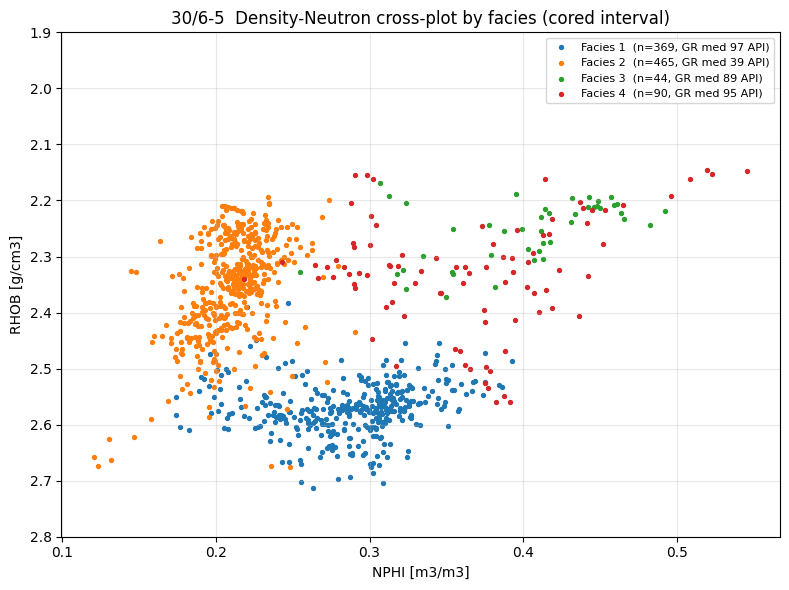

In [15]:
# FACIES is a category, so no colorbar: one scatter series per facies with a
# discrete colour, and the fingerprint (n, median GR) carried in the legend.
nphi_s, rhob_s, gr_s = features['NPHI'], features['RHOB'], features['GR']

fig, ax = plt.subplots(figsize=(8, 6))
palette = plt.get_cmap('tab10').colors
for k, fc in enumerate(np.unique(result.facies[result.facies > 0])):
    sel = result.facies == fc
    ax.scatter(nphi_s[sel], rhob_s[sel], s=8, color=palette[k],
               label='Facies %d  (n=%d, GR med %.0f API)'
                     % (fc, sel.sum(), np.nanmedian(gr_s[sel])))
ax.set_xlabel('NPHI [m3/m3]')
ax.set_ylabel('RHOB [g/cm3]')
ax.set_ylim(2.8, 1.9)   # density increases downward
ax.grid(alpha=0.3)
ax.legend(loc='upper right', fontsize=8)
ax.set_title('30/6-5  Density-Neutron cross-plot by facies (cored interval)')
plt.tight_layout()
plt.show()

## Pitfalls and parameter choices

- **Calibrate against an *independent* log.** Comparing a curve against itself
  gives a meaningless $R^2 = 1$. We built density porosity from RHOB specifically
  so the comparison against core `PHIC` is real.
- **Depth-matching.** Core depth and log depth are rarely on the same datum; a
  small shift can destroy an otherwise good correlation. `calibrate_porosity`
  interpolates the log to the core depths - always sanity-check the tie.
- **Poro-perm is log-linear.** Never fit permeability in linear space; a few
  high-perm plugs will dominate the least-squares fit. `fit_poro_perm_transform`
  works in $\log_{10}$ for exactly this reason.
- **K-means needs scaling and sensible K.** `DigitalCoreFacies` standardises
  features for you, but *you* choose `n_facies` and the weights. Too many facies
  over-fits noise; too few merges distinct rock types.

## Recap

- `core_data_from_well` pulled 200+ real plugs off 30/6-5 into a `CoreData`.
- Density porosity calibrated against core with a modest bias and $R^2 \approx 0.65$,
  exposing the assumed-matrix-density error.
- A $\log_{10}(k)=A\phi+B$ transform propagated a handful of core-perm plugs to
  a continuous predicted-permeability curve.
- `DigitalCoreFacies` clustered real wireline logs into facies with a per-facies
  statistics fingerprint and a readable density-neutron cross-plot.

## Try it yourself

> **Exercise 1.** Re-run the porosity calibration using a *neutron* porosity
> (`well.get('NPHI')`) instead of density porosity. Which log ties the core
> better, and what does the bias tell you about gas or clay effects?
>
> **Exercise 2.** Change `n_facies` in `DigitalCoreFacies` to 6 and add `PEF` to
> the weights. Does the inertia drop meaningfully, or are you just splitting
> noise? Inspect the new per-facies statistics table.
>
> **Exercise 3.** Feed the fitted `transform` a corrected porosity
> (via `corr.predict`) instead of raw `PHID`. How much does the predicted
> permeability profile shift?

## What's next

Continue with **13 - ML Curve Imputation**, where a pretrained gradient-boosted
model fills gaps in a missing log curve - the machine-learning counterpart to the
physics-based calibration you just did.